In [ ]:
# %% [markdown]
# # Demand Forecasting - Statistical + Top-down + Baseline
# Models ที่เทียบกัน (ใช้ backtest เดียวกัน):
#   1) YearlyNaive  : ยอดขายวันเดียวกัน (weekday เดียวกัน) ของปีก่อน  -> baseline
#   2) SeasonalNaive: ทำซ้ำสัปดาห์ล่าสุด (statsforecast)
#   3) AutoETS      : exponential smoothing ต่อ series (statsforecast)
#   4) TopDown      : forecast ยอดรวมด้วย MSTL แล้วแบ่งสัดส่วนตาม store-item x day-of-week
#   5) TopDown_YoY  : ยอดรวมวันเดียวกันปีก่อน x อัตราโต YoY แล้วแบ่งสัดส่วน
#   6) TopDown_Mult : log(ยอดรวม) = trend + เดือน + วันในสัปดาห์ แล้วแบ่งสัดส่วน
#   7) TopDown_Ens  : เฉลี่ย TopDown_YoY กับ TopDown_Mult แบบ 50:50

In [2]:
# %% 1) Config + imports
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive, MSTL
 
DATA_PATH = "train.csv"          # วาง train.csv ไว้โฟลเดอร์เดียวกับ notebook; columns: date, store, item, sales
N_JOBS = -1                      # ใช้ทุก core
USE_MSTL_FOR_TOTAL = True        # ถ้า MSTL error ให้ตั้งเป็น False (จะใช้ AutoETS แทน)
 
# 12 anchors: 2015-01-01 ... 2017-10-01 (ทุก 3 เดือน)
ANCHORS = pd.date_range("2015-01-01", "2017-10-01", freq="QS")
print(list(ANCHORS.strftime("%Y-%m-%d")))

['2015-01-01', '2015-04-01', '2015-07-01', '2015-10-01', '2016-01-01', '2016-04-01', '2016-07-01', '2016-10-01', '2017-01-01', '2017-04-01', '2017-07-01', '2017-10-01']


In [3]:
# %% 2) Load data -> long format ที่ statsforecast ใช้ (unique_id, ds, y)
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
raw = raw.sort_values(["store", "item", "date"]).reset_index(drop=True)
raw["unique_id"] = raw["store"].astype(str) + "_" + raw["item"].astype(str)

long = raw[["unique_id", "date", "sales"]].rename(columns={"date": "ds", "sales": "y"})
print(long.shape, long["unique_id"].nunique(), "series")
print(long["ds"].min(), "->", long["ds"].max())

# เช็กว่าทุก series มีวันครบ ไม่ขาด (statsforecast ต้องการ daily ต่อเนื่อง)
days = long["ds"].nunique()
counts = long.groupby("unique_id")["ds"].count()
print("series ที่วันไม่ครบ:", int((counts != days).sum()))


(913000, 3) 500 series
2013-01-01 00:00:00 -> 2017-12-31 00:00:00
series ที่วันไม่ครบ: 0


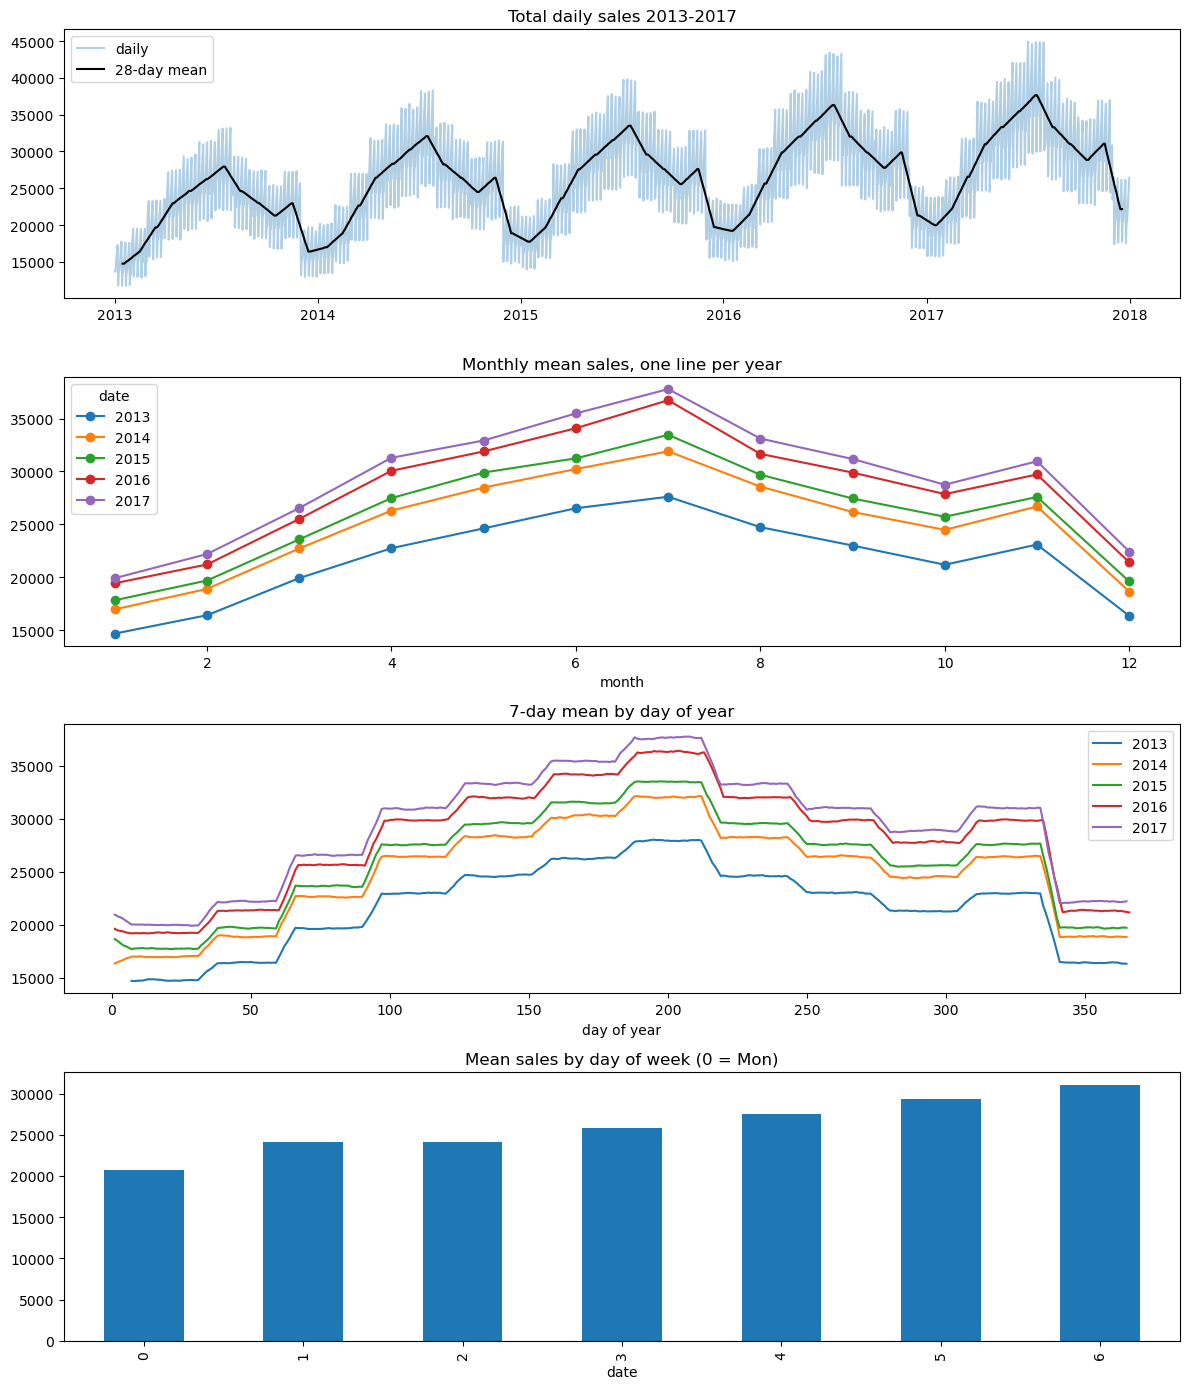

In [4]:
# %% 2b) EDA: ยอดรวมทุก store-item -> trend, seasonality รายปี, รอบรายสัปดาห์
tot = raw.groupby('date')['sales'].sum()

fig, ax = plt.subplots(4, 1, figsize=(12, 14))

# 1) ยอดรวมรายวัน + ค่าเฉลี่ย 28 วัน -> trend และ seasonality ภาพรวม
ax[0].plot(tot, alpha=0.35, label="daily")
ax[0].plot(tot.rolling(28, center=True).mean(), color="black", label="28-day mean")
ax[0].set_title("Total daily sales 2013-2017"); ax[0].legend()

# 2) ค่าเฉลี่ยรายเดือน ซ้อนทีละปี -> seasonality รายปี และ growth
m = tot.groupby([tot.index.year, tot.index.month]).mean().unstack(0)
m.plot(ax=ax[1], marker="o")
ax[1].set_title("Monthly mean sales, one line per year"); ax[1].set_xlabel("month")

# 3) 7-day mean ซ้อนทีละปีตาม day of year -> ดูว่า pattern เกิดทุกปีไหม
w = tot.rolling(7).mean()
for y in range(2013, 2018):
    s = w[str(y)]
    ax[2].plot(s.index.dayofyear, s.values, label=str(y))
ax[2].set_title("7-day mean by day of year"); ax[2].set_xlabel("day of year"); ax[2].legend()

# 4) ยอดเฉลี่ยตามวันในสัปดาห์
tot.groupby(tot.index.dayofweek).mean().plot(kind="bar", ax=ax[3])
ax[3].set_title("Mean sales by day of week (0 = Mon)")

plt.tight_layout(); plt.show()

In [5]:
# %% 3) Metrics
def smape(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float)
    denom = np.abs(a) + np.abs(f)
    return 100 * np.mean(np.where(denom == 0, 0, 2 * np.abs(f - a) / denom))

def metrics(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float)
    return {
        "SMAPE": smape(a, f),
        "RMSE": float(np.sqrt(np.mean((f - a) ** 2))),
        "MAE": float(np.mean(np.abs(f - a))),
    }

In [6]:
# %% 4) Models
def fc_yearly_naive(train, future_dates):
    """baseline: ค่าของวันเดียวกัน (364 วันก่อน = weekday เดียวกัน)"""
    lookup = train.set_index(["unique_id", "ds"])["y"]
    uids = train["unique_id"].unique()
    out = pd.MultiIndex.from_product([uids, future_dates], names=["unique_id", "ds"]).to_frame(index=False)
    src = out[["unique_id"]].copy()
    src["ds"] = out["ds"] - pd.Timedelta(days=364)
    out["yhat"] = lookup.reindex(pd.MultiIndex.from_frame(src)).to_numpy()
    # กันกรณีไม่มีข้อมูลปีก่อน: ใช้ค่าเฉลี่ยของ series นั้น
    mean_by_id = train.groupby("unique_id")["y"].mean()
    out["yhat"] = out["yhat"].fillna(out["unique_id"].map(mean_by_id))
    return out[["unique_id", "ds", "yhat"]]


def fc_stat_models(train, h):
    """AutoETS + SeasonalNaive(7) ต่อ series ด้วย statsforecast"""
    sf = StatsForecast(
        models=[AutoETS(season_length=7), SeasonalNaive(season_length=7)],
        freq="D",
        n_jobs=N_JOBS,
    )
    fc = sf.forecast(df=train, h=h)
    if "unique_id" not in fc.columns:        # statsforecast เวอร์ชันเก่าเก็บ unique_id ไว้ใน index
        fc = fc.reset_index()
    res = {}
    for name in ["AutoETS", "SeasonalNaive"]:
        res[name] = fc[["unique_id", "ds", name]].rename(columns={name: "yhat"})
    return res


def forecast_total(total_df, h):
    """forecast ยอดรวมทุก store-item (series เดียว)"""
    if USE_MSTL_FOR_TOTAL:
        model = MSTL(season_length=[7, 365], trend_forecaster=AutoETS(model="ZZN"))
    else:
        model = AutoETS(season_length=7)
    sf = StatsForecast(models=[model], freq="D", n_jobs=1)
    fc = sf.forecast(df=total_df, h=h)
    if "ds" not in fc.columns:
        fc = fc.reset_index()
    col = [c for c in fc.columns if c not in ("unique_id", "ds")][0]
    return fc.rename(columns={col: "total_hat"})[["ds", "total_hat"]]


def dow_shares(train, lookback=365):
    """สัดส่วนยอดขายของแต่ละ store-item ต่อยอดรวม แยกตาม day-of-week (จาก lookback วันล่าสุด)"""
    recent = train[train["ds"] > train["ds"].max() - pd.Timedelta(days=lookback)].copy()
    recent["dow"] = recent["ds"].dt.dayofweek
    num = recent.groupby(["unique_id", "dow"])["y"].sum()
    den = recent.groupby("dow")["y"].sum()
    return (num / den.reindex(num.index.get_level_values("dow")).to_numpy()).rename("share").reset_index()


def split_total(total_fc, share):
    """total_fc: [ds, total_hat] -> forecast ต่อ store-item = total_hat x share"""
    out = total_fc.assign(dow=total_fc["ds"].dt.dayofweek).merge(share, on="dow")
    out["yhat"] = out["total_hat"].clip(lower=0) * out["share"]
    return out[["unique_id", "ds", "yhat"]]


def daily_total(train):
    return train.groupby("ds")["y"].sum()


def fc_topdown(train, future_dates, lookback=365):
    """Top-down A: forecast ยอดรวมด้วย MSTL แล้วแบ่งสัดส่วน"""
    total = daily_total(train).reset_index()
    total.insert(0, "unique_id", "total")
    tfc = forecast_total(total, len(future_dates))
    return split_total(tfc, dow_shares(train, lookback))


def fc_topdown_yoy(train, future_dates, lookback=365, growth_days=91):
    """Top-down B: ยอดรวมวันเดียวกันปีก่อน (364 วันก่อน) x อัตราโต YoY
    (อัตราโตวัดจาก growth_days วันล่าสุด เทียบกับช่วงเดียวกันของปีก่อน) แล้วแบ่งสัดส่วน"""
    T = daily_total(train)
    last = T.index.max()
    recent = T[T.index > last - pd.Timedelta(days=growth_days)]
    prev = T.reindex(recent.index - pd.Timedelta(days=364))
    g = recent.sum() / prev.sum()
    fd = pd.DatetimeIndex(future_dates)
    total_hat = T.reindex(fd - pd.Timedelta(days=364)).to_numpy() * g
    tfc = pd.DataFrame({"ds": fd, "total_hat": total_hat})
    return split_total(tfc, dow_shares(train, lookback))


def _design(dates, t0):
    """ตัวแปรของ log-linear model: ค่าคงที่, trend (ปี), เดือน (dummy), วันในสัปดาห์ (dummy)"""
    d = pd.DatetimeIndex(dates)
    cols = {"const": np.ones(len(d)), "t": (d - t0).days.to_numpy() / 365.0}
    for m in range(2, 13):
        cols[f"m{m}"] = (d.month == m).astype(float)
    for w in range(1, 7):
        cols[f"w{w}"] = (d.dayofweek == w).astype(float)
    return pd.DataFrame(cols, index=d)


def fc_topdown_mult(train, future_dates, lookback=365):
    """Top-down C: log(ยอดรวม) = trend + ผลของเดือน + ผลของวันในสัปดาห์ (แบบคูณ)
    ตรงกับโครงสร้างที่เห็นใน EDA (ขั้นบันไดตามเดือน, โตแบบคูณ) แล้วแบ่งสัดส่วน"""
    T = daily_total(train)
    t0 = T.index.min()
    X = _design(T.index, t0)
    y = np.log(T.clip(lower=1)).to_numpy()
    beta, *_ = np.linalg.lstsq(X.to_numpy(), y, rcond=None)
    Xf = _design(future_dates, t0)
    tfc = pd.DataFrame({"ds": pd.DatetimeIndex(future_dates),
                        "total_hat": np.exp(Xf.to_numpy() @ beta)})
    return split_total(tfc, dow_shares(train, lookback))


def average_preds(*preds):
    """เฉลี่ย yhat ของหลาย model ราย (unique_id, ds)"""
    return pd.concat(preds).groupby(["unique_id", "ds"], as_index=False)["yhat"].mean()


def fc_topdown_ens(train, future_dates, lookback=365):
    """Top-down D: เฉลี่ย forecast ของ TopDown_YoY กับ TopDown_Mult"""
    return average_preds(fc_topdown_yoy(train, future_dates, lookback),
                         fc_topdown_mult(train, future_dates, lookback))


In [7]:
# %% 5) Backtest (rolling origin, horizon = 3 เดือน)
SAVE_PREDS = ["TopDown", "TopDown_YoY", "TopDown_Mult", "TopDown_Ens"]  # เก็บ prediction ทุก anchor

def run_backtest(long, anchors):
    rows, saved, last = [], [], None
    for anchor in anchors:
        t0 = time.time()
        end = anchor + pd.DateOffset(months=3)
        future_dates = pd.date_range(anchor, end - pd.Timedelta(days=1))
        train = long[long["ds"] < anchor]
        actual = long[(long["ds"] >= anchor) & (long["ds"] < end)]

        preds = {"YearlyNaive": fc_yearly_naive(train, future_dates)}
        preds.update(fc_stat_models(train, len(future_dates)))
        preds["TopDown"] = fc_topdown(train, future_dates)
        preds["TopDown_YoY"] = fc_topdown_yoy(train, future_dates)
        preds["TopDown_Mult"] = fc_topdown_mult(train, future_dates)
        preds["TopDown_Ens"] = average_preds(preds["TopDown_YoY"], preds["TopDown_Mult"])

        saved_m = actual.copy()
        for name, p in preds.items():
            m = actual.merge(p, on=["unique_id", "ds"], how="inner")
            assert len(m) == len(actual), f"{name}: forecast ไม่ครบ ({len(m)} vs {len(actual)})"
            rows.append({"anchor": anchor, "model": name,
                         **metrics(m["y"], m["yhat"].clip(lower=0))})
            if name in SAVE_PREDS:
                saved_m = saved_m.merge(p.rename(columns={"yhat": name}), on=["unique_id", "ds"])
        saved.append(saved_m.assign(anchor=anchor))
        last = (actual, preds)
        print(f"{anchor.date()} เสร็จ ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows), pd.concat(saved, ignore_index=True), last

# ลองกับ anchor เดียวก่อนเพื่อเช็กว่าไม่พัง (เร็ว): 
# res_test, _, _ = run_backtest(long, ANCHORS[-1:])
# res_test

results, backtest_preds, last_run = run_backtest(long, ANCHORS)
results.to_csv("backtest_results.csv", index=False)
backtest_preds.to_csv("backtest_preds.csv", index=False)


2015-01-01 เสร็จ (35s)


2015-04-01 เสร็จ (38s)


2015-07-01 เสร็จ (39s)


2015-10-01 เสร็จ (42s)


2016-01-01 เสร็จ (45s)


2016-04-01 เสร็จ (48s)


... (2 outputs left out)

2017-01-01 เสร็จ (58s)


2017-04-01 เสร็จ (62s)


2017-07-01 เสร็จ (67s)


2017-10-01 เสร็จ (71s)


                SMAPE           RMSE            MAE       
                 mean    std    mean    std    mean    std
model                                                     
AutoETS        19.211  3.336  13.003  2.759   9.929  2.328
SeasonalNaive  22.246  3.315  14.567  2.583  11.159  2.109
TopDown        12.989  1.712   8.186  0.743   6.297  0.536
TopDown_Ens    12.586  1.662   7.814  0.525   6.047  0.414
TopDown_Mult   12.759  1.497   7.969  0.666   6.175  0.516
TopDown_YoY    12.677  1.780   7.919  0.458   6.089  0.371
YearlyNaive    17.987  1.604  11.065  1.104   8.505  0.851

model       AutoETS  SeasonalNaive  TopDown  TopDown_Ens  TopDown_Mult  \
anchor                                                                   
2015-01-01    19.00          23.01    17.18        16.69         16.42   
2015-04-01    23.23          26.23    12.05        11.92         12.65   
2015-07-01    14.54          17.52    11.58        11.63         12.00   
2015-10-01    20.97          23.36    1

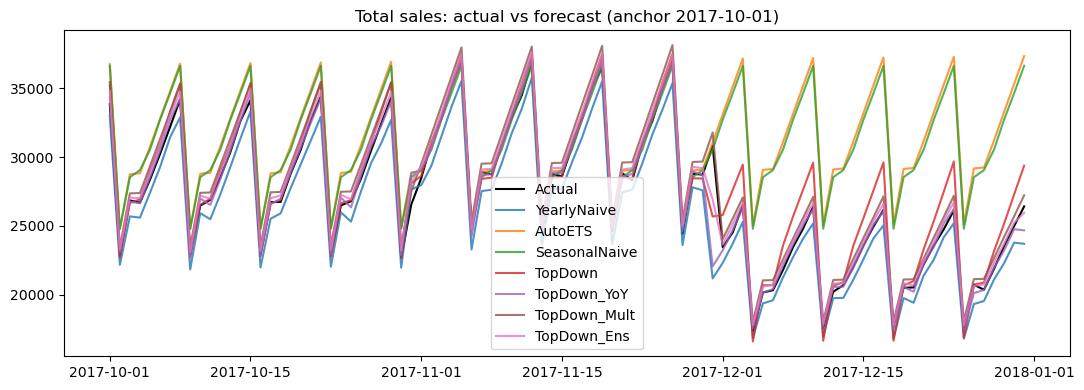

In [8]:
# %% 6) สรุปผล
summary = (results.groupby("model")[["SMAPE", "RMSE", "MAE"]]
           .agg(["mean", "std"]).round(3))
print(summary)
print()
print(results.pivot(index="anchor", columns="model", values="SMAPE").round(2))

# %% 7) กราฟ: ยอดรวมจริง vs forecast ของ anchor สุดท้าย
actual, preds = last_run
plt.figure(figsize=(11, 4))
plt.plot(actual.groupby("ds")["y"].sum(), label="Actual", color="black")
for name, p in preds.items():
    plt.plot(p.groupby("ds")["yhat"].sum().clip(lower=0), label=name, alpha=0.8)
plt.title(f"Total sales: actual vs forecast (anchor {ANCHORS[-1].date()})")
plt.legend()
plt.tight_layout()
plt.show()



saved forecast_2018_TopDown_Ens.csv (45000, 4)
   store  item       date      sales
0      1     1 2018-01-01  12.383642
1      1     1 2018-01-02  14.473778
2      1     1 2018-01-03  15.067792
3      1     1 2018-01-04  16.289773
4      1     1 2018-01-05  16.473983
growth g (2017/2016) = 1.0364
   2017_actual    2017_x_g  2018_forecast  forecast / (2017 x g)
1       617306  639750.868     656148.565                  1.026
2       621369  643961.597     667266.934                  1.036
3       822667  852578.669     889755.702                  1.044


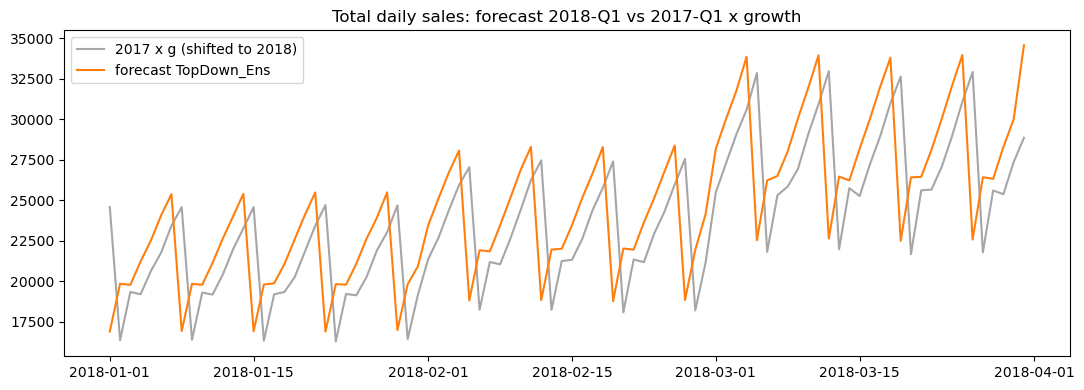

In [9]:
# %% 8) Forecast จริง 2018-01-01 .. 2018-03-31 ด้วย model ที่เลือก
# เกณฑ์ (ตั้งไว้ก่อนดูผล Ens): 1) SMAPE เฉลี่ย 12 anchors ต่ำสุด
#   2) ถ้าต่างกัน < ~0.1 เลือกตัวที่ดีกว่าใน anchor ม.ค.  3) ถ้ายังเท่ากัน เลือกตัวที่ง่ายกว่า
# ผล: Ens 12.586 < YoY 12.676 (ต่าง 0.09) -> ดู ม.ค.: Ens 14.86 < YoY 15.11 -> TopDown_Ens
BEST = "TopDown_Ens"
future_dates = pd.date_range("2018-01-01", "2018-03-31")

FUNCS = {"TopDown": fc_topdown, "TopDown_YoY": fc_topdown_yoy, "TopDown_Mult": fc_topdown_mult,
         "TopDown_Ens": fc_topdown_ens, "YearlyNaive": fc_yearly_naive}
if BEST in FUNCS:
    final = FUNCS[BEST](long, future_dates)
else:
    final = fc_stat_models(long, len(future_dates))[BEST]

final["yhat"] = final["yhat"].clip(lower=0)
ids = raw[["unique_id", "store", "item"]].drop_duplicates()
final = (final.merge(ids, on="unique_id")
              .rename(columns={"ds": "date", "yhat": "sales"})
              [["store", "item", "date", "sales"]]
              .sort_values(["store", "item", "date"])
              .reset_index(drop=True))
assert final.shape == (45000, 4)
assert final["sales"].notna().all()
assert final["date"].min() == pd.Timestamp("2018-01-01") and final["date"].max() == pd.Timestamp("2018-03-31")
out_path = f"forecast_2018_{BEST}.csv"
final.to_csv(out_path, index=False)
print("saved", out_path, final.shape)
print(final.head())

# %% 9) Sanity check: ยอดรวมรายเดือน 2018 เทียบกับ ม.ค.-มี.ค. 2017 x อัตราโต (ยอดรวมปี 2017 / ปี 2016)
T = daily_total(long)
g = T["2017"].sum() / T["2016"].sum()
fc_total = final.groupby("date")["sales"].sum()
chk = pd.DataFrame({
    "2017_actual": T["2017-01":"2017-03"].groupby(T["2017-01":"2017-03"].index.month).sum(),
    "2017_x_g": T["2017-01":"2017-03"].groupby(T["2017-01":"2017-03"].index.month).sum() * g,
    "2018_forecast": fc_total.groupby(fc_total.index.month).sum(),
})
chk["forecast / (2017 x g)"] = chk["2018_forecast"] / chk["2017_x_g"]
print(f"growth g (2017/2016) = {g:.4f}")
print(chk.round(3))

plt.figure(figsize=(11, 4))
plt.plot(T["2017-01":"2017-03"].index + pd.DateOffset(years=1), T["2017-01":"2017-03"].to_numpy() * g,
         label="2017 x g (shifted to 2018)", color="gray", alpha=0.7)
plt.plot(fc_total, label=f"forecast {BEST}", color="C1")
plt.title("Total daily sales: forecast 2018-Q1 vs 2017-Q1 x growth")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# %% 10) Oracle test: ถ้ารู้ยอดรวมจริงของช่วง forecast จะเหลือ error เท่าไร (เพดานของ top-down)
# Oracle ใช้ข้อมูลอนาคต จึงไม่ใช่ model ใช้แค่วัดว่า error มาจากการทายยอดรวมกี่ส่วน
def smape_terms(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float)
    denom = np.abs(a) + np.abs(f)
    return 100 * np.where(denom == 0, 0, 2 * np.abs(f - a) / denom)

oracle_frames, share_frames = [], []
for anchor in ANCHORS:
    end = anchor + pd.DateOffset(months=3)
    train = long[long["ds"] < anchor]
    actual = long[(long["ds"] >= anchor) & (long["ds"] < end)]
    share = dow_shares(train)
    true_total = daily_total(actual).rename("total_hat").reset_index()
    oracle_frames.append(split_total(true_total, share).rename(columns={"yhat": "Oracle"}).assign(anchor=anchor))
    # share ที่ใช้ เทียบกับ share จริงในช่วง horizon
    a = actual.assign(dow=actual["ds"].dt.dayofweek)
    num = a.groupby(["unique_id", "dow"])["y"].sum()
    act_share = num / a.groupby("dow")["y"].sum().reindex(num.index.get_level_values("dow")).to_numpy()
    share_frames.append(share.merge(act_share.rename("share_actual").reset_index(), on=["unique_id", "dow"]).assign(anchor=anchor))

ea = backtest_preds.merge(pd.concat(oracle_frames), on=["unique_id", "ds", "anchor"])
EA_MODELS = ["TopDown", "TopDown_YoY", "TopDown_Mult", "TopDown_Ens", "Oracle"]
for c in EA_MODELS:
    ea[f"sm_{c}"] = smape_terms(ea["y"], ea[c].clip(lower=0))
SM = [f"sm_{c}" for c in EA_MODELS]

per_anchor = ea.groupby("anchor")[SM].mean().rename(columns=lambda c: c[3:])
print(per_anchor.agg(["mean", "std"]).round(3))
gap = per_anchor["TopDown_Ens"].mean() - per_anchor["Oracle"].mean()
print(f"\nส่วนที่มาจากการทายยอดรวม (Ens - Oracle) = {gap:.2f} SMAPE")
print(f"ส่วนที่เป็น noise ระดับ store-item-วัน (Oracle) = {per_anchor['Oracle'].mean():.2f} SMAPE")

      TopDown  TopDown_YoY  TopDown_Mult  TopDown_Ens  Oracle
mean   12.989       12.677        12.759       12.586  12.160
std     1.712        1.780         1.497        1.662   1.082

ส่วนที่มาจากการทายยอดรวม (Ens - Oracle) = 0.43 SMAPE
ส่วนที่เป็น noise ระดับ store-item-วัน (Oracle) = 12.16 SMAPE


In [11]:
# %% 11) Error analysis: error กระจุกตรงไหน และมี bias ไหม
ea = ea.merge(raw[["unique_id", "store", "item"]].drop_duplicates(), on="unique_id")
ea["h_month"] = (ea["ds"].dt.month - ea["anchor"].dt.month) + 1   # เดือนที่ 1-3 ของ horizon
ea["dow"] = ea["ds"].dt.dayofweek

def by(col):
    return ea.groupby(col)[SM].mean().rename(columns=lambda c: c[3:]).round(2)

print("=== SMAPE ตามเดือนใน horizon ===");  print(by("h_month"))
print("\n=== SMAPE ตาม day-of-week (0 = จันทร์) ===");  print(by("dow"))
print("\n=== SMAPE ตาม store ===");  print(by("store"))
item_sm = by("item")
print("\n=== item ดีสุด / แย่สุด 5 ตัว (ตาม Ens) ===")
print(item_sm.sort_values("TopDown_Ens").iloc[np.r_[0:5, -5:0]])
print("corr(ยอดขายเฉลี่ยของ item, SMAPE ของ item) =",
      round(np.corrcoef(ea.groupby("item")["y"].mean(), item_sm["TopDown_Ens"])[0, 1], 3))

# bias (forecast สูง/ต่ำเกินเป็นระบบไหม) ใน anchor ม.ค.
jan = ea[ea["anchor"].dt.month == 1]
print("\n=== bias ใน anchor ม.ค. (+ = forecast สูงเกิน) ===")
for c in EA_MODELS:
    e = jan[c].clip(lower=0) - jan["y"]
    print(f"{c:13s} {e.mean():+.2f} ชิ้น/วัน  ({100 * e.sum() / jan['y'].sum():+.1f}%)")

# share นิ่งไหม
sh = pd.concat(share_frames)
sh["abs_pct"] = 100 * (sh["share"] - sh["share_actual"]).abs() / sh["share_actual"]
print("\nshare ที่ใช้คลาดจาก share จริงเฉลี่ย", round(sh["abs_pct"].mean(), 2), "%  (ต่อ anchor:",
      sh.groupby("anchor")["abs_pct"].mean().round(1).min(), "-", sh.groupby("anchor")["abs_pct"].mean().round(1).max(), "%)")

=== SMAPE ตามเดือนใน horizon ===


         TopDown  TopDown_YoY  TopDown_Mult  TopDown_Ens  Oracle
h_month                                                         
1          13.05        12.64         12.79        12.60   12.20
2          12.71        12.65         12.57        12.43   12.00
3          13.18        12.72         12.90        12.70   12.27

=== SMAPE ตาม day-of-week (0 = จันทร์) ===
     TopDown  TopDown_YoY  TopDown_Mult  TopDown_Ens  Oracle
dow                                                         
0      14.05        14.09         14.11        13.95   13.55
1      13.05        13.27         13.20        13.09   12.61
2      13.06        13.00         13.10        12.91   12.52
3      12.85        12.66         12.72        12.55   12.12
4      12.74        12.22         12.38        12.18   11.77
5      12.62        11.94         12.06        11.88   11.44
6      12.49        11.52         11.71        11.49   11.10

=== SMAPE ตาม store ===
       TopDown  TopDown_YoY  TopDown_Mult  TopDown_Ens  O

In [12]:
# %% 12) Prediction interval P10 / P90 จาก residual ของ backtest
# ratio = ยอดจริง / forecast ต่อ store-item -> quantile 10% / 90% -> คูณกับ forecast 2018
Q_LO, Q_HI = 0.10, 0.90
bt = backtest_preds[backtest_preds[BEST] > 0].copy()
bt["ratio"] = bt["y"] / bt[BEST]

def ratio_quantiles(df):
    return (df.groupby("unique_id")["ratio"].quantile([Q_LO, Q_HI]).unstack()
              .rename(columns={Q_LO: "q_lo", Q_HI: "q_hi"}))

def coverage(test, q):
    t = test.merge(q, left_on="unique_id", right_index=True)
    lo, hi = t[BEST] * t["q_lo"], t[BEST] * t["q_hi"]
    return pd.Series({"ใน P10-P90 % (เป้า 80)": 100 * ((t["y"] >= lo) & (t["y"] <= hi)).mean(),
                      "ต่ำกว่า P90 % (เป้า 90)": 100 * (t["y"] <= hi).mean(),
                      "ต่ำกว่า P10 % (เป้า 10)": 100 * (t["y"] < lo).mean(),
                      "กว้างเฉลี่ย (ชิ้น)": (hi - lo).mean()})

# ตรวจแบบไม่ใช้ข้อมูลอนาคต: quantile จาก anchor 2015-2016 -> วัดบน anchor 2017
q_train = ratio_quantiles(bt[bt["anchor"].dt.year <= 2016])
test = bt[bt["anchor"].dt.year == 2017]
cov = {"ทั้งปี 2017": coverage(test, q_train)}
cov.update({str(a.date()): coverage(g, q_train) for a, g in test.groupby("anchor")})
print(pd.DataFrame(cov).T.round(1))

# quantile สุดท้ายจากทั้ง 12 anchors -> ใช้กับ forecast 2018 (final จาก cell 8)
q_all = ratio_quantiles(bt)
pi = final.assign(unique_id=final["store"].astype(str) + "_" + final["item"].astype(str))
pi = pi.merge(q_all, left_on="unique_id", right_index=True, how="left")
pi["p10"], pi["p90"] = pi["sales"] * pi["q_lo"], pi["sales"] * pi["q_hi"]
pi = pi[["store", "item", "date", "sales", "p10", "p90"]]
assert pi.shape == (45000, 6) and pi.notna().all().all()
assert (pi["p10"] <= pi["sales"]).all() and (pi["sales"] <= pi["p90"]).all()
pi.to_csv(f"forecast_2018_{BEST}_PI.csv", index=False)
print(f"\nsaved forecast_2018_{BEST}_PI.csv", pi.shape)
print(pi.head())
# หมายเหตุ: P10/P90 เป็นช่วงราย store-item ต่อวัน เอามาบวกกันเป็นช่วงของยอดรวมไม่ได้

             ใน P10-P90 % (เป้า 80)  ต่ำกว่า P90 % (เป้า 90)  \
ทั้งปี 2017                    82.2                     91.5   
2017-01-01                     77.3                     92.3   
2017-04-01                     85.3                     92.4   
2017-07-01                     85.5                     92.0   
2017-10-01                     80.6                     89.3   

             ต่ำกว่า P10 % (เป้า 10)  กว้างเฉลี่ย (ชิ้น)  
ทั้งปี 2017                      9.3                21.0  
2017-01-01                      15.0                16.8  
2017-04-01                       7.0                23.6  
2017-07-01                       6.4                24.1  
2017-10-01                       8.7                19.3  



saved forecast_2018_TopDown_Ens_PI.csv (45000, 6)
   store  item       date      sales        p10        p90
0      1     1 2018-01-01  12.383642   8.681719  15.593410
1      1     1 2018-01-02  14.473778  10.147037  18.225298
2      1     1 2018-01-03  15.067792  10.563479  18.973277
3      1     1 2018-01-04  16.289773  11.420164  20.511987
4      1     1 2018-01-05  16.473983  11.549308  20.743944
